# Döner or Matcha? — a taste index of gentrification
**#30DayMapChallenge · Senses: Taste**

A riff on Sam Floy's 2015 *Fried Chicken Method* for London, which compared coffee shops to fried chicken shops as a playful proxy for gentrification.
Here the "old neighbourhood" food is the **Döner kebab** and the "new arrival" is the **matcha bar**.

**Pipeline:** places data → points → hex grid → smoothed log-ratio index → diverging map.

**Two data sources** (set `SOURCE` in the config):
* `"overture"` *(default)* — [Overture Maps](https://overturemaps.org) Places: free, open business POIs merged from Meta, Microsoft, Foursquare and others. Usually much denser for cafés/takeaways than OSM. Downloaded straight from Overture's cloud bucket.
* `"osm"` — OpenStreetMap via Overpass. Community-mapped, great in Germany, but sparser for trendy new cafés.

Everything city- or food-specific lives in the `CONFIG` cell, so swapping Berlin for another city or matcha/döner for another pairing is a one-cell change.

> ⚠️ A playful proxy, not a measurement. OSM undercounts small independents, and treating immigrant food culture as a marker of "undesirability" is exactly the critique the original method got. Worth a line in your post.

In [152]:
# !pip install geopandas osmnx contextily matplotlib requests overturemaps
import json, hashlib, time
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import requests
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from shapely.geometry import Polygon, Point

## 1 · Config — pick a city and a pairing

In [154]:
# Each preset has, for both foods A and B:
#   pattern — regex matched against name + category text (used by SOURCE="overture")
#   recipe  — Overpass statements, unioned (used by SOURCE="osm")
CHAINS = (r"starbucks|balzac|einstein|coffee fellows|tchibo|mccaf|woyton|dunkin|costa coffee|caff[eè] nero|"
          r"segafredo|lavazza|back[- ]?factory|backwerk|kamps|ditsch|steinecke|le crobag|wiener feinb|"
          r"extrablatt|espresso house|bagel brothers|dean ?& ?david|nespresso")

# Overture files many non-cafés under "coffee_shop" (sushi, pizza delivery, CBD shops, machine dealers...).
# Names containing any of these words are not counted as coffee places.
NOT_COFFEE = (r"restaurant|sushi|pizz|burger|d[öo]ner|kebab|kebap|imbiss|lieferservice|bringdienst|"
              r"indisch|asiat|thai|vietnam|china|chines|cbd|hanf|gmbh|automat|maschinen|kaffeeservice|"
              r"vending|gro(ß|ss)handel|catering|hotel|hostel|b[äa]ckerei|konditorei|eis ?caf|gelato|"
              r"gew[üu]rz|supermarkt|kiosk|sp[äa]ti|tankstelle|bar & grill|grill")

PRESETS = {
    "berlin_coffee": dict(
        title="Döner or Flat White (Berlin edition)",
        tagline="Adapted from Sam Floy's Gentri-Fried Chicken (2015)",
        subtitle="Berlin",
        area='area["name"="Berlin"]["boundary"="administrative"]["admin_level"="4"]',
        boundary_place="Berlin, Germany",
        A=dict(label="Döner", color="#C4502A",
               pattern=r"d[öo]ner|kebab|kebap|d[üu]r[üu]m|turkish_restaurant|türkisch",
               recipe=[
            'nwr["amenity"~"^(fast_food|restaurant)$"]["cuisine"~"kebab|doner|döner|dürüm|durum|turkish",i]',
            'nwr["amenity"~"^(fast_food|restaurant)$"]["name"~"döner|doner|kebab|kebap|dürüm",i]',
        ]),
        # Independent coffee: coffee-shop / roaster categories, or coffee-ish names — chains excluded
        B=dict(label="Independent coffee", short="coffee", color="#2E6E73", color_name="teal",
               pattern=r"coffee_shop|coffee_roaster|coffee|kaffee|espresso|r[öo]ster",
               exclude=CHAINS + "|" + NOT_COFFEE,
               recipe=[
            'nwr["amenity"="cafe"]["cuisine"~"coffee",i]["brand"!~"."]',
            'nwr["amenity"="cafe"]["name"~"coffee|kaffee|espresso|roast|röster",i]["brand"!~"."]',
            'nwr["craft"="coffee_roaster"]',
            'nwr["shop"="coffee"]["brand"!~"."]',
        ]),
        hex_m=900,
        districts={"boundary": "administrative", "admin_level": "10"},   # Ortsteile
        ring="S41",                                                       # Ringbahn, for focus + outline
        districts_wfs="https://gdi.berlin.de/services/wfs/alkis_ortsteile",  # official Berlin Ortsteile (tried first)
        labels=["Mitte", "Prenzlauer Berg", "Friedrichshain", "Kreuzberg", "Neukölln", "Wedding",
                "Gesundbrunnen", "Moabit", "Schöneberg", "Charlottenburg", "Tiergarten", "Lichtenberg"],
        labels_city=["Mitte", "Spandau", "Reinickendorf", "Pankow", "Marzahn", "Köpenick", "Steglitz",
                     "Zehlendorf", "Tempelhof", "Neukölln", "Lichtenberg", "Charlottenburg", "Kreuzberg", "Prenzlauer Berg"],
    ),
    "berlin": dict(
        title="Döner or Matcha?",
        subtitle="Berlin",
        area='area["name"="Berlin"]["boundary"="administrative"]["admin_level"="4"]',
        boundary_place="Berlin, Germany",
        A=dict(label="Döner", color="#B5541C",
               pattern=r"d[öo]ner|kebab|kebap|d[üu]r[üu]m|turkish_restaurant|türkisch",
               recipe=[
            'nwr["amenity"~"^(fast_food|restaurant)$"]["cuisine"~"kebab|doner|döner|dürüm|durum",i]',
            'nwr["amenity"~"^(fast_food|restaurant)$"]["name"~"döner|doner|kebab|kebap|dürüm",i]',
        ]),
        B=dict(label="Matcha", color="#5E8C31",
               pattern=r"matcha|抹茶",
               recipe=[
            'nwr["amenity"~"^(cafe|restaurant|fast_food|ice_cream)$"]["name"~"matcha|抹茶",i]',
            'nwr["amenity"~"^(cafe|restaurant|fast_food|ice_cream)$"]["cuisine"~"matcha",i]',
            'nwr["shop"~"^(tea|coffee)$"]["name"~"matcha|抹茶",i]',
            'nwr["drink:matcha"="yes"]',
        ]),
        hex_m=900,
        districts={"boundary": "administrative", "admin_level": "10"},   # Ortsteile
        ring="S41",                                                       # Ringbahn, for focus + outline
        districts_wfs="https://gdi.berlin.de/services/wfs/alkis_ortsteile",  # official Berlin Ortsteile (tried first)
        labels=["Mitte", "Prenzlauer Berg", "Friedrichshain", "Kreuzberg", "Neukölln", "Wedding",
                "Gesundbrunnen", "Moabit", "Schöneberg", "Charlottenburg", "Tiergarten", "Lichtenberg"],
        labels_city=["Mitte", "Spandau", "Reinickendorf", "Pankow", "Marzahn", "Köpenick", "Steglitz",
                     "Zehlendorf", "Tempelhof", "Neukölln", "Lichtenberg", "Charlottenburg", "Kreuzberg", "Prenzlauer Berg"],
    ),
    "nyc": dict(
        title="Bodega or Matcha?",
        subtitle="New York City",
        area='area["name"="City of New York"]["boundary"="administrative"]["admin_level"="5"]',
        boundary_place="New York City, New York, USA",
        A=dict(label="Bodega", color="#B5541C",
               pattern=r"bodega|\bdeli\b|convenience",
               recipe=[
            'nwr["shop"~"^(convenience|deli)$"]',
        ]),
        B=dict(label="Matcha", color="#5E8C31",
               pattern=r"matcha|抹茶",
               recipe=[
            'nwr["amenity"~"^(cafe|restaurant|fast_food|ice_cream)$"]["name"~"matcha|抹茶",i]',
            'nwr["amenity"~"^(cafe|restaurant|fast_food)$"]["cuisine"~"matcha",i]',
            'nwr["drink:matcha"="yes"]',
        ]),
        hex_m=1000,
    ),
    "cdmx": dict(
        title="Taquería or Matcha?",
        subtitle="Mexico City",
        area='area["name"="Ciudad de México"]["boundary"="administrative"]["admin_level"="4"]',
        boundary_place="Ciudad de México, Mexico",
        A=dict(label="Taquería", color="#B5541C",
               pattern=r"taquer|\btacos?\b|taco_restaurant",
               recipe=[
            'nwr["amenity"~"^(fast_food|restaurant)$"]["cuisine"~"taco|mexican",i]',
            'nwr["amenity"~"^(fast_food|restaurant)$"]["name"~"taquer|tacos",i]',
        ]),
        B=dict(label="Matcha", color="#5E8C31",
               pattern=r"matcha|抹茶",
               recipe=[
            'nwr["amenity"~"^(cafe|restaurant|fast_food|ice_cream)$"]["name"~"matcha|抹茶",i]',
            'nwr["drink:matcha"="yes"]',
        ]),
        hex_m=1200,
    ),
}

CITY = "berlin_coffee"        # or "berlin" (döner vs matcha), "nyc", "cdmx"
CFG = PRESETS[CITY]
SOURCE = "overture"         # "overture" or "osm"

SPECIALTY_COFFEE = [         # OSM version: unbranded coffee shops
    'nwr["amenity"="cafe"]["cuisine"~"coffee_shop|specialty",i]["brand"!~"."]',
]
SPECIALTY_COFFEE_PATTERN = r"coffee_shop|coffee_roaster|specialty coffee"   # Overture version (unbranded only)
OVERTURE_MIN_CONFIDENCE = 0.3   # Overture gives each place a 0–1 confidence; drops stale/dubious listings

# Matcha is a menu item, not a business category — name matching only finds places with "matcha" in the name.
# Optionally widen the "new arrival" side (label on the map updates to match):
B_EXTRA = []                     # any of: "tea_rooms", "specialty_coffee"
B_EXTRA_PATTERNS = {             # Overture
    "tea_rooms": r"tea_room|teahouse|tea house|teehaus|teestube|japanese.{0,12}caf",
    "specialty_coffee": SPECIALTY_COFFEE_PATTERN,
}
B_EXTRA_RECIPES = {              # OSM
    "tea_rooms": ['nwr["amenity"="cafe"]["cuisine"~"tea|japanese",i]', 'nwr["shop"="tea"]'],
    "specialty_coffee": SPECIALTY_COFFEE,
}
INCLUDE_B = set()                # Overture ids to add by hand (see the near-miss list below)

MIN_POINTS_PER_HEX = 2      # grey out hexes with fewer total places (noise)
MIN_POINTS_PER_DISTRICT = 4 # same for neighbourhoods
FOCUSES = ["ring", "city"]  # one set of maps per entry: "ring" (inside the S-Bahn ring, from OSM), "city", or a (w, s, e, n) lon/lat box you choose
PRIOR_K = 2                 # smoothing strength: each hex is shrunk toward the city mix as if it had K extra places
# overpass-api.de now rejects generic clients (HTTP 406) — identify yourself, and fall back to mirrors
OVERPASS_URLS = [
    "https://overpass-api.de/api/interpreter",
    "https://overpass.kumi.systems/api/interpreter",
    "https://overpass.private.coffee/api/interpreter",
]
OVERPASS_HEADERS = {
    "User-Agent": "30DayMapChallenge-taste-index/1.0 (personal map project; contact: you@example.com)",
    "Referer": "https://30daymapchallenge.com/",
    "Accept": "*/*",
}
CACHE = Path("cache"); CACHE.mkdir(exist_ok=True)

## 2 · City boundary

In [156]:
import osmnx as ox
boundary = ox.geocode_to_gdf(CFG["boundary_place"])[["geometry"]]   # via Nominatim
crs = boundary.estimate_utm_crs()
bbox_4326 = tuple(boundary.total_bounds)                            # (minx, miny, maxx, maxy) for Overture
boundary = boundary.to_crs(crs)

## 3 · Fetch places (cached to `cache/`)

In [158]:
import re

def _txt(v):
    """Flatten Overture's nested struct/list columns into one searchable string."""
    if v is None or (isinstance(v, float) and np.isnan(v)): return ""
    if isinstance(v, dict): return " ".join(_txt(x) for x in v.values())
    if isinstance(v, (list, tuple, np.ndarray)): return " ".join(_txt(x) for x in v)
    return str(v)

def fetch_overture(bbox):
    path = CACHE / f"overture_places_{CITY}.parquet"
    if path.exists():
        return gpd.read_parquet(path)
    from overturemaps import core
    print("Downloading Overture places for bbox", [round(x, 3) for x in bbox], "— can take a few minutes…")
    g = core.geodataframe("place", bbox=bbox)
    g = g.set_crs(4326, allow_override=True)
    g.to_parquet(path)
    return g

def overture_subset(places, pattern, label, unbranded_only=False):
    p = places
    if "confidence" in p: p = p[p["confidence"].fillna(0) >= OVERTURE_MIN_CONFIDENCE]
    if "operating_status" in p: p = p[p["operating_status"].fillna("open").isin(["open"])]
    name = p["names"].map(lambda d: (d or {}).get("primary") if isinstance(d, dict) else None)
    # Match on the name + each place's MAIN category only. Alternate categories and website/social
    # links are ignored — they pulled in bakeries, spice shops etc. that merely mention coffee.
    def main_cats(r):
        out = []
        for c in ("categories", "taxonomy"):
            v = r.get(c)
            if isinstance(v, dict) and v.get("primary"): out.append(str(v["primary"]))
        v = r.get("basic_category")
        if isinstance(v, str): out.append(v)
        return " ".join(out)
    cats = p.apply(main_cats, axis=1) if len(p) else pd.Series(dtype=str)
    text = (name.fillna("") + " " + cats).str.lower()
    m = text.str.contains(pattern, flags=re.I, regex=True)
    if unbranded_only and "brand" in p: m &= p["brand"].isna()
    out = gpd.GeoDataFrame(dict(osm_id=p["id"], name=name, amenity=None, cuisine=cats),
                           geometry=p.geometry, crs=4326)[m.values]
    out["kind"] = label
    return out.drop_duplicates("osm_id")

def overpass(statements, area, timeout=180):
    """Union of statements inside an area; returns JSON elements (with centers for ways/relations)."""
    body = "".join(f"  {s}(area.a);\n" for s in statements)
    q = f"[out:json][timeout:{timeout}];\n{area}->.a;\n(\n{body});\nout center tags;"
    key = CACHE / (hashlib.md5(q.encode()).hexdigest() + ".json")
    if key.exists():
        return json.loads(key.read_text())["elements"]
    last = None
    for url in OVERPASS_URLS:
        for attempt in range(2):
            r = requests.post(url, data={"data": q}, headers=OVERPASS_HEADERS, timeout=timeout + 30)
            if r.status_code == 200:
                key.write_text(r.text)
                return r.json()["elements"]
            print(f"{url.split('/')[2]} → HTTP {r.status_code}"); last = r
            if r.status_code in (406, 403): break        # blocked here; try next mirror
            time.sleep(10 * (attempt + 1))
    last.raise_for_status()

def osm_to_gdf(elements, label):
    rows = []
    for e in elements:
        lat = e.get("lat", e.get("center", {}).get("lat"))
        lon = e.get("lon", e.get("center", {}).get("lon"))
        if lat is None: continue
        t = e.get("tags", {})
        rows.append(dict(osm_id=f'{e["type"]}/{e["id"]}', name=t.get("name"),
                         amenity=t.get("amenity") or t.get("shop"), cuisine=t.get("cuisine"),
                         lon=lon, lat=lat))
    df = pd.DataFrame(rows).drop_duplicates("osm_id")
    g = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.lon, df.lat), crs=4326)
    g["kind"] = label
    return g

if SOURCE == "overture":
    places = fetch_overture(bbox_4326)
    print(f"{len(places):,} Overture places in bbox")
    A = overture_subset(places, CFG["A"]["pattern"], CFG["A"]["label"])
    B = overture_subset(places, CFG["B"]["pattern"], CFG["B"]["label"],
                        unbranded_only="exclude" in CFG["B"])
    for extra in B_EXTRA:
        B = pd.concat([B, overture_subset(places, B_EXTRA_PATTERNS[extra], CFG["B"]["label"],
                                          unbranded_only=True)]).drop_duplicates("osm_id")
    if INCLUDE_B:
        B = pd.concat([B, overture_subset(places[places["id"].isin(INCLUDE_B)], r".", CFG["B"]["label"])]).drop_duplicates("osm_id")
else:
    recipe_B = CFG["B"]["recipe"] + sum((B_EXTRA_RECIPES[e] for e in B_EXTRA), [])
    A = osm_to_gdf(overpass(CFG["A"]["recipe"], CFG["area"]), CFG["A"]["label"])
    B = osm_to_gdf(overpass(recipe_B, CFG["area"]), CFG["B"]["label"])

# Drop chains / anything matching a preset's exclude pattern (both sources)
for side, df in (("A", "A"), ("B", "B")):
    ex = CFG[side].get("exclude")
    if ex:
        g_ = globals()[df]
        drop = g_["name"].fillna("").str.contains(ex, case=False, regex=True)
        print(f"{CFG[side]['label']}: dropped {drop.sum()} chain/excluded places")
        globals()[df] = g_[~drop]

if B_EXTRA:
    CFG["B"]["label"] = "Matcha & " + " & ".join(e.replace("_", " ") for e in B_EXTRA)
    B["kind"] = CFG["B"]["label"]

# a place matching both patterns (e.g. "Matcha & Döner") counts once, as B
A = A[~A.osm_id.isin(B.osm_id)]

# Remove duplicate listings: same name within ~100 m (Overture often has a place twice)
def dedupe(g):
    if g.empty: return g
    xy = g.to_crs(3857).geometry
    key = pd.DataFrame({"n": g["name"].fillna("").str.lower().str.strip(),
                        "x": (xy.x // 100).astype(int), "y": (xy.y // 100).astype(int)}, index=g.index)
    keep = ~key.duplicated() | (key["n"] == "")
    if (~keep).sum(): print(f"{g['kind'].iloc[0]}: dropped {(~keep).sum()} duplicate listings")
    return g[keep]
A, B = dedupe(A), dedupe(B)

# Full lists for checking in Excel / a text editor
for g_, lab in ((A, "A"), (B, "B")):
    g_[["osm_id", "name", "cuisine"]].sort_values("name").to_csv(CACHE / f"matched_{CITY}_{lab}.csv", index=False)
print("Full matched lists saved to", CACHE)
print(f'{CFG["A"]["label"]}: {len(A)}   {CFG["B"]["label"]}: {len(B)}')

266,541 Overture places in bbox
Independent coffee: dropped 203 chain/excluded places
Döner: dropped 4 duplicate listings
Independent coffee: dropped 1 duplicate listings
Full matched lists saved to cache
Döner: 998   Independent coffee: 582


C:\Users\User\AppData\Local\Temp\ipykernel_15888\2569723160.py:100: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  drop = g_["name"].fillna("").str.contains(ex, case=False, regex=True)


### Diagnostics — why are the numbers what they are? *(Overture only)*
How many matches each filter removes and which categories they carry. The near-miss list (cafés/tea places that *might* serve matcha) is mainly for the matcha preset — copy ids into `INCLUDE_B` and re-run.

In [160]:
if SOURCE == "overture":
    pd.set_option("display.max_colwidth", 60)
    nm = places["names"].map(lambda d: (d or {}).get("primary") if isinstance(d, dict) else None).fillna("")
    cat = places["categories"].map(lambda d: (d or {}).get("primary") if isinstance(d, dict) else None) \
          if "categories" in places else pd.Series("", index=places.index)
    conf = places.get("confidence", pd.Series(1.0, index=places.index)).fillna(0)

    for lab, pat in [(CFG["A"]["label"], CFG["A"]["pattern"]), (CFG["B"]["label"], CFG["B"]["pattern"])]:
        raw = overture_subset(places.assign(confidence=1.0), pat, lab)
        print(f"\n{lab}: {len(raw)} matches before confidence filter")
        for t in (0.0, 0.2, 0.3, 0.5, 0.7):
            print(f"   confidence ≥ {t}: {(conf[places['id'].isin(raw.osm_id)] >= t).sum()}")
        print("   top categories:", cat[places["id"].isin(raw.osm_id)].value_counts().head(8).to_dict())

    # Uncategorised döner-ish names, and what share of places have no category at all
    print(f"\nPlaces with no category: {cat.isna().mean():.0%}")

    near = places[cat.fillna("").str.contains("cafe|coffee|tea|dessert|bakery|japanese|bubble", case=False)
                  & nm.str.contains(r"cha\b|\btea|\btee|japan|kyoto|tokyo|\buji|green|matsu|kissa|sabo|ocha|mochi|wagashi", case=False)
                  & ~places["id"].isin(B.osm_id)]
    print(f"\n{len(near)} near-miss candidates for B (review, then add ids to INCLUDE_B):")
    display(pd.DataFrame({"id": near["id"], "name": nm[near.index], "category": cat[near.index],
                          "confidence": conf[near.index].round(2)}).sort_values("name").head(80))


Döner: 1019 matches before confidence filter
   confidence ≥ 0.0: 1019
   confidence ≥ 0.2: 1016
   confidence ≥ 0.3: 1002
   confidence ≥ 0.5: 968
   confidence ≥ 0.7: 529
   top categories: {'': 1019}

Independent coffee: 1515 matches before confidence filter
   confidence ≥ 0.0: 1515
   confidence ≥ 0.2: 1507
   confidence ≥ 0.3: 1484
   confidence ≥ 0.5: 1423
   confidence ≥ 0.7: 1108
   top categories: {'': 1515}

Places with no category: 0%

0 near-miss candidates for B (review, then add ids to INCLUDE_B):


,id,name,category,confidence


Sanity-check what got matched — tagging is messy, so eyeball the names and drop false positives.

In [162]:
display(B[["name", "cuisine"]].sort_values("name").head(40))
display(A["name"].value_counts().head(15))

,name,cuisine
127612,1838 Deli,coffee_shop coffee_shop
142875,19grams Alex,coffee_shop coffee_shop
165048,3 Monate Coffee,coffee_shop coffee_shop
51101,ARS-Musica-Berlin Kaffeehaus,cafe cafe
148672,Abo Garaba,coffee_shop coffee_shop
125047,Adot Kitchen - Authentic Ethiopian Brunch And Speciality...,ethiopian_restaurant restaurant
124560,Aeka Berlin,coffee_shop coffee_shop
49011,Agni Roastery ­| Mikro-kaffeerösterei,coffee_roastery coffee_shop
110641,Akka Breakfast | Smoothie | Coffeeshop,coffee_shop coffee_shop
110639,Akka Freshbar Und Coffeeshop,coffee_shop coffee_shop


name
Imren Grill                     5
Hakiki                          4
Fatih Servet                    4
Prime Kebap                     3
K.bap                           3
Prime Kebab                     3
Osmans Töchter                  3
Hasir Restaurant                3
Istanbul Grill                  3
Mustafa Demir's Gemüse Kebap    3
Mevlüt's Döner                  2
Bistro Femo                     2
Mega Bistro                     2
Bey Simit Haus                  2
Sofra Grill                     2
Name: count, dtype: int64

In [163]:
# Manual exclusions (id or exact name) if anything wrong slipped in
EXCLUDE = set()
A = A[~A.osm_id.isin(EXCLUDE) & ~A.name.isin(EXCLUDE)]
B = B[~B.osm_id.isin(EXCLUDE) & ~B.name.isin(EXCLUDE)]

## 4 · Spatial units: hexagons *and* neighbourhoods (Ortsteile)

In [165]:
pts = pd.concat([A, B]).to_crs(crs)
pts = pts[pts.within(boundary.union_all())]

def hex_grid(bounds, size):
    """Flat-topped hexagons; `size` = centre-to-centre spacing in metres."""
    minx, miny, maxx, maxy = bounds
    r = size / np.sqrt(3)                     # circumradius
    dx, dy = 1.5 * r, size
    cells = []
    for i, x in enumerate(np.arange(minx - r, maxx + r, dx)):
        off = dy / 2 if i % 2 else 0
        for y in np.arange(miny - dy, maxy + dy, dy):
            cy = y + off
            ang = np.deg2rad(np.arange(0, 360, 60))
            cells.append(Polygon(zip(x + r * np.cos(ang), cy + r * np.sin(ang))))
    return gpd.GeoDataFrame(geometry=cells, crs=crs)

hexes = hex_grid(boundary.total_bounds, CFG["hex_m"])
hexes = hexes[hexes.intersects(boundary.union_all())].reset_index(drop=True)
hexes["uid"] = hexes.index
print(len(hexes), "hexes")

1413 hexes


In [166]:
# Neighbourhood polygons from OSM (Berlin: 96 Ortsteile, admin_level=10), cached.
# Uses our own Overpass request (same headers + mirrors as everything else) rather than osmnx,
# whose header settings differ between versions and can trigger the 406 block.
from shapely.ops import polygonize, unary_union
from shapely.geometry import LineString

def _post_overpass(q, timeout=60):
    for url in OVERPASS_URLS:
        try:
            r = requests.post(url, data={"data": q}, headers=OVERPASS_HEADERS, timeout=timeout)
            if r.status_code == 200:
                return r
            print(f"{url.split('/')[2]} → HTTP {r.status_code}")
        except requests.RequestException as e:
            print(f"{url.split('/')[2]} → {e}")
    return None

def _relation_polygon(el):
    ways = {"outer": [], "inner": []}
    for m in el.get("members", []):
        if m.get("type") == "way" and len(m.get("geometry", [])) > 1:
            ways["inner" if m.get("role") == "inner" else "outer"].append(
                LineString([(g["lon"], g["lat"]) for g in m["geometry"]]))
    if not ways["outer"]:
        return None
    shape = unary_union(list(polygonize(unary_union(ways["outer"]))))
    if ways["inner"]:
        shape = shape.difference(unary_union(list(polygonize(unary_union(ways["inner"])))))
    return None if shape.is_empty else shape

import io

def fetch_districts_wfs(base):
    """Official boundaries from a WFS (Berlin: ALKIS Ortsteile from gdi.berlin.de)."""
    hdr = {"User-Agent": OVERPASS_HEADERS["User-Agent"]}
    try:
        caps = requests.get(base, params={"service": "WFS", "request": "GetCapabilities"}, headers=hdr, timeout=60)
        layers = re.findall(r"<(?:wfs:)?FeatureType\b.*?<(?:wfs:)?Name>([^<]+)</", caps.text, flags=re.S)
    except requests.RequestException as e:
        print("WFS unreachable:", e); return None
    if not layers:
        print("WFS: no layers found"); return None
    for version, key in (("2.0.0", "typeNames"), ("1.1.0", "typeName")):
        for fmt in ("application/json", "json", None):          # None = default GML
            params = {"service": "WFS", "version": version, "request": "GetFeature", key: layers[0]}
            if fmt: params["outputFormat"] = fmt
            try:
                r = requests.get(base, params=params, headers=hdr, timeout=120)
                if r.status_code != 200 or b"Exception" in r.content[:500]:
                    continue
                d = gpd.read_file(io.BytesIO(r.content))
            except Exception:
                continue
            if d.empty:
                continue
            # Coordinates in metres mean ETRS89 / UTM 33N (Berlin's default), even if the file claims lon/lat
            if abs(d.total_bounds[0]) > 1000:
                d = d.set_crs(25833, allow_override=True)
            elif d.crs is None:
                d = d.set_crs(4326)
            # the name column is whichever text column contains the most known neighbourhood names
            known = set(CFG.get("labels", []) + CFG.get("labels_city", []))
            texts = [c for c in d.columns if c != "geometry"
                     and (d[c].dtype == object or pd.api.types.is_string_dtype(d[c]))]
            if not texts:
                continue
            name_col = max(texts, key=lambda c: d[c].astype(str).isin(known).sum())
            print(f"Neighbourhoods from WFS layer '{layers[0]}' ({len(d)} shapes, names from '{name_col}')")
            return d[[name_col, "geometry"]].rename(columns={name_col: "name"})
    print("WFS: could not download features"); return None

def fetch_districts():
    tags = CFG.get("districts")
    if not tags:
        return None
    path = CACHE / f"districts_{CFG['boundary_place'].split(',')[0].lower()}.gpkg"
    if path.exists():
        return gpd.read_file(path).to_crs(crs)
    d = fetch_districts_wfs(CFG.get("districts_wfs")) if CFG.get("districts_wfs") else None
    if d is not None:
        d = d.to_crs(crs)
        d = d[d.representative_point().within(boundary.buffer(200).union_all())]
        if len(d):
            d.to_file(path)
            return d
        print("WFS shapes didn't line up with the city boundary — ignoring them")
    print("Trying OpenStreetMap for neighbourhoods…")
    filt = "".join(f'["{k}"="{v}"]' for k, v in tags.items())
    r = _post_overpass(f"[out:json][timeout:180];\n{CFG['area']}->.a;\nrelation{filt}(area.a);\nout geom;")
    if r is None:
        print("Could not fetch neighbourhoods — skipping that map"); return None
    rows = [(el.get("tags", {}).get("name"), _relation_polygon(el)) for el in r.json()["elements"]]
    d = gpd.GeoDataFrame([{"name": n, "geometry": g} for n, g in rows if n and g is not None], crs=4326)
    if d.empty:
        print("No neighbourhood polygons returned — skipping that map"); return None
    d = d.to_crs(crs)
    d = d[d.representative_point().within(boundary.union_all())]     # drop neighbours outside the city
    if d.empty:
        print("No neighbourhoods inside the city boundary — skipping that map"); return None
    d.to_file(path)
    return d

districts = fetch_districts()
if districts is not None:
    districts = districts.reset_index(drop=True)
    districts["uid"] = districts.index
    print(len(districts), "neighbourhoods")

97 neighbourhoods


In [167]:
# Focus area: the S-Bahn ring (fetched from OSM) or the whole city
def overpass_raw(q, timeout=45):
    key = CACHE / (hashlib.md5(q.encode()).hexdigest() + ".json")
    if key.exists():
        return json.loads(key.read_text())["elements"]
    for url in OVERPASS_URLS:
        try:
            r = requests.post(url, data={"data": q}, headers=OVERPASS_HEADERS, timeout=timeout)
            if r.status_code == 200:
                key.write_text(r.text); return r.json()["elements"]
            print(f"{url.split('/')[2]} → HTTP {r.status_code}")
        except requests.RequestException as e:
            print(f"{url.split('/')[2]} → {e}")
    return None

from shapely.geometry import LineString, MultiLineString, box
from shapely.ops import linemerge

# The inner-city outline comes only from real data, in this order:
#   1. Berlin's official environmental zone (Umweltzone = the area inside the S-Bahn ring),
#      downloaded as GeoJSON from Geoportal Berlin / ArcGIS Hub and saved as UMWELTZONE_FILE
#   2. the Ringbahn track from OpenStreetMap: a file you exported (RING_FILE) or a live Overpass request
# If none of these is available, there is no line and no inner-city view — nothing is guessed.
# Looks in the notebook folder and in cache/ for any GeoJSON with "umweltzone" in its name
_uz = sorted(f for d in (Path("."), CACHE) for f in d.glob("*.geojson") if "umweltzone" in f.name.lower())
UMWELTZONE_FILE = _uz[0] if _uz else CACHE / "umweltzone_berlin.geojson"
RING_FILE = CACHE / "ringbahn_osm.geojson"
ring, RING_LABEL = None, None
if UMWELTZONE_FILE.exists():
    g_uz = gpd.read_file(UMWELTZONE_FILE)
    g_uz = g_uz[g_uz.geom_type.isin(["Polygon", "MultiPolygon"])]
    if len(g_uz):
        g_uz = g_uz.set_crs(4326) if g_uz.crs is None else g_uz
        ring = gpd.GeoSeries([g_uz.geometry.union_all().boundary], crs=g_uz.crs).to_crs(crs)
        RING_LABEL = "Umweltzone (inside the S-Bahn ring), Geoportal Berlin"
        print("Inner-city outline from", UMWELTZONE_FILE)
if ring is None and RING_FILE.exists():
    g_ring = gpd.read_file(RING_FILE)
    g_ring = g_ring[g_ring.geom_type.isin(["LineString", "MultiLineString"])]
    if len(g_ring):
        geom = g_ring.geometry.union_all()
        if geom.geom_type == "MultiLineString":
            geom = linemerge(geom)
        ring = gpd.GeoSeries([geom], crs=g_ring.crs or 4326).to_crs(crs)
        RING_LABEL = "Ringbahn (OpenStreetMap)"
        print("Ringbahn from", RING_FILE)
if ring is None and CFG.get("ring"):
    print("Fetching the Ringbahn from OpenStreetMap…")
    w, s_, e, n = bbox_4326
    els = overpass_raw(f'[out:json][timeout:60];relation["route"~"train|light_rail"]["ref"="{CFG["ring"]}"]'
                       f'({s_},{w},{n},{e});out geom;')
    lines = [LineString([(g["lon"], g["lat"]) for g in m["geometry"]])
             for el in (els or []) for m in el.get("members", [])
             if m.get("type") == "way" and len(m.get("geometry", [])) > 1]
    if lines:
        ring = gpd.GeoSeries([linemerge(MultiLineString(lines))], crs=4326).to_crs(crs)
        RING_LABEL = "Ringbahn (OpenStreetMap)"

def get_extent(focus):
    if focus == "ring" and ring is not None:
        return ring.buffer(1500).total_bounds
    if focus == "ring":
        return None            # no real ring data → no inner-city view
    if isinstance(focus, (tuple, list)):
        return gpd.GeoSeries([box(*focus)], crs=4326).to_crs(crs).total_bounds
    pad = 800
    minx, miny, maxx, maxy = boundary.total_bounds
    return np.array([minx - pad, miny - pad, maxx + pad, maxy + pad])

if ring is not None:
    print("Inner-city line:", RING_LABEL)
else:
    print("No inner-city outline — the inner-city maps will be skipped.")
    print("To fix, either save Berlin's Umweltzone GeoJSON (ArcGIS Hub / Geoportal Berlin) next to this notebook")
    print("or, in a browser, run this at "
          "https://overpass-turbo.eu, then Export → GeoJSON → save as", RING_FILE)
    print(f'  [out:json];relation["route"~"train|light_rail"]["ref"="{CFG.get("ring", "S41")}"]'
          f'({bbox_4326[1]},{bbox_4326[0]},{bbox_4326[3]},{bbox_4326[2]});out geom;')

Inner-city outline from umweltzone_berlin.geojson
Inner-city line: Umweltzone (inside the S-Bahn ring), Geoportal Berlin


## 5 · The index

For each unit (hex or neighbourhood), with $p$ = city-wide share of B and $K$ = prior strength:
$\displaystyle \text{index} = \log_2\!\left(\frac{(B+Kp)\,/\,(A+K(1-p))}{p\,/\,(1-p)}\right)$

* **0** → the unit has the city-wide mix (units with few places are shrunk toward 0)
* **+1** → twice as B-leaning as the city overall; **−1** → twice as A-leaning

Normalising by the city ratio matters: one side usually outnumbers the other everywhere, so a raw ratio would paint the whole city one colour.

In [169]:
la, lb = CFG["A"]["label"], CFG["B"]["label"]
p = (pts.kind == lb).sum() / len(pts)            # city-wide share of B
city_ratio = p / (1 - p)

def score(layer, min_n):
    j = gpd.sjoin(pts, layer[["uid", "geometry"]], predicate="within")
    counts = j.groupby(["uid", "kind"]).size().unstack(fill_value=0)
    for c in (la, lb):
        if c not in counts: counts[c] = 0
    out = layer.drop(columns=[la, lb], errors="ignore").join(counts[[la, lb]], on="uid").fillna({la: 0, lb: 0})
    out["index"] = np.log2(((out[lb] + PRIOR_K * p) / (out[la] + PRIOR_K * (1 - p))) / city_ratio)
    out["n"] = out[la] + out[lb]
    out["shown"] = out.n >= min_n
    return out

hexes = score(hexes, MIN_POINTS_PER_HEX)
print(f"City ratio {lb}/{la} = {city_ratio:.3f}; hexes shown: {hexes.shown.sum()} of {len(hexes)}")
if districts is not None:
    districts = score(districts, MIN_POINTS_PER_DISTRICT)
    display(districts[districts.shown].sort_values("index", ascending=False)[["name", la, lb, "index"]].round(2).head(12))
    display(districts[districts.shown].sort_values("index")[["name", la, lb, "index"]].round(2).head(12))

City ratio Independent coffee/Döner = 0.595; hexes shown: 219 of 1413


,name,Döner,Independent coffee,index
17,Buch,1.0,4.0,1.82
8,Tiergarten,5.0,11.0,1.66
29,Schmargendorf,1.0,3.0,1.48
72,Bohnsdorf,1.0,3.0,1.48
53,Friedenau,1.0,3.0,1.48
6,Mitte,51.0,78.0,1.34
21,Prenzlauer Berg,39.0,53.0,1.17
25,Charlottenburg,51.0,62.0,1.01
26,Halensee,2.0,3.0,0.95
75,Biesdorf,2.0,3.0,0.95


,name,Döner,Independent coffee,index
55,Buckow,15.0,0.0,-3.70
48,Marienfelde,7.0,0.0,-2.72
85,Friedrichsfelde,6.0,0.0,-2.53
33,Haselhorst,5.0,0.0,-2.32
83,Neu-Hohenschönhausen,5.0,0.0,-2.32
39,Spandau,26.0,3.0,-2.11
41,Lankwitz,4.0,0.0,-2.07
12,Wilhelmsruh,4.0,0.0,-2.07
92,Märkisches Viertel,4.0,0.0,-2.07
24,Westend,9.0,1.0,-1.81


## 6 · The maps — hexagons, neighbourhoods, and the raw dots

In [171]:
import contextily as cx
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D

BG, INK, MUTED = "#FAF6EE", "#2B2620", "#6A6152"
cA, cB = CFG["A"]["color"], CFG["B"]["color"]
cmap = LinearSegmentedColormap.from_list("taste", [cA, "#EFE6D2", cB])
sa, sb = CFG["A"].get("short", la), CFG["B"].get("short", lb)
SOURCE_NOTE = "Data: Overture Maps Foundation" if SOURCE == "overture" else "Data © OpenStreetMap contributors"
plt.rcParams["font.family"] = "DejaVu Sans"

def label_points(names):
    """Label positions come only from the real neighbourhood polygons; no polygons → no labels."""
    out = {}
    if districts is None:
        return out
    for name in names:
        match = districts[districts.name == name]
        if len(match):
            pt = match.geometry.iloc[0].representative_point()
            out[name] = (pt.x, pt.y)
        else:
            print(f"  label '{name}' not found in the neighbourhood data — skipped")
    return out

LABEL_SIZE = 8.5

def base_figure(title, subtitle, width=11, top_in=1.35, bottom_in=1.05):
    """Figure sized to the extent's aspect ratio, so there are no dead margins."""
    minx, miny, maxx, maxy = extent
    map_w = width * 0.94
    map_h = map_w * (maxy - miny) / (maxx - minx)
    H = map_h + top_in + bottom_in
    fig = plt.figure(figsize=(width, H), facecolor=BG)
    ax = fig.add_axes([0.03, bottom_in / H, 0.94, map_h / H])
    ax.set_facecolor(BG); ax.set_axis_off()
    ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)
    boundary.plot(ax=ax, color="#F1EBDD", edgecolor="none", zorder=1)
    try:
        cx.add_basemap(ax, crs=crs, source=cx.providers.Esri.WorldGrayCanvas, alpha=0.4, zorder=2,
                       attribution=False)   # tile credit moved into the footer instead
    except Exception as e:
        print("basemap skipped:", e)
    ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)
    boundary.boundary.plot(ax=ax, color="#8C8270", linewidth=0.8, zorder=2.5)
    fig.text(0.03, (H - 0.25) / H, title, fontsize=28, weight="bold", color=INK, va="top")
    fig.text(0.03, (H - 0.85) / H, subtitle, fontsize=12.5, color="#5A5246", va="top")
    return fig, ax, H

def overlay(ax, label_color=INK):
    if ring is not None:
        ring.plot(ax=ax, color=INK, linewidth=1.1, linestyle=(0, (4, 2.5)), alpha=0.55, zorder=6)
    halo = [pe.withStroke(linewidth=3, foreground=BG, alpha=0.9)]
    minx, miny, maxx, maxy = extent
    for name, (x, y) in LABELS.items():
        if minx < x < maxx and miny < y < maxy:
            ax.text(x, y, name.upper(), fontsize=LABEL_SIZE, weight="bold", color=label_color, ha="center",
                    va="center", path_effects=halo, zorder=7)

def footer(fig, H, unit_note, unit="area"):
    # Left, under the colour scale: how to read the map, in plain words
    nb_, na_ = CFG["B"].get("color_name", "green"), CFG["A"].get("color_name", "red")
    fig.text(0.03, 0.22 / H,
             f"Each {unit} compares its mix of {lb.lower()} and {la.lower()} shops\n"
             f"with {CFG['subtitle']} as a whole. {nb_.capitalize()} = more {sb.lower()} than the city average,\n"
             f"{na_} = more {sa.lower()}. Areas with very few shops to conclude are shown grey.",
             ha="left", va="bottom", fontsize=8.5, color="#4A433A", linespacing=1.5)
    # Right: counts and credits
    fig.text(0.97, 0.22 / H,
             f"{(pts.kind==la).sum():,} {la.lower()} · {(pts.kind==lb).sum():,} {lb.lower()} places · {unit_note}\n"
             f"{SOURCE_NOTE}\n"
             + (f"Dashed line: {RING_LABEL}" if ring is not None else ""),
             ha="right", va="bottom", fontsize=8, color=MUTED, linespacing=1.5)

def legend_bar(fig, H, norm):
    cax = fig.add_axes([0.03, 1.02 / H, 0.32, 0.17 / H])
    cb = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), cax=cax, orientation="horizontal")
    cb.set_ticks([norm.vmin, 0, norm.vmax])
    cb.set_ticklabels([f"more {sa}", "city average", f"more {sb}"])
    cb.outline.set_visible(False); cax.tick_params(labelsize=10, colors="#3A342C", length=0)
    lbls = cax.get_xticklabels(); lbls[0].set_ha("left"); lbls[-1].set_ha("right")

def make_norm(layer):
    lim = max(1.5, np.nanpercentile(np.abs(layer.loc[layer.shown, "index"]), 95))
    return TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)

def index_map(layer, unit, unit_note, out, edge="#FAF6EE", lw=0.6):
    fig, ax, H = base_figure(CFG["title"], CFG.get("tagline", f'{CFG["subtitle"]} · {lb.lower()} vs. {la.lower()} shops, by {unit}'),
                             bottom_in=1.55)   # room for legend + how-to-read text
    norm = make_norm(layer)
    thin = layer[~layer.shown & (layer.n > 0)] if unit == "hexagon" else layer[~layer.shown]   # empty hexes stay invisible
    thin.plot(ax=ax, color="#E6DFD0", edgecolor=edge, linewidth=lw, alpha=0.6, zorder=3)
    layer[layer.shown].plot(ax=ax, column="index", cmap=cmap, norm=norm, edgecolor=edge,
                            linewidth=lw, alpha=0.93, zorder=4)
    overlay(ax)
    legend_bar(fig, H, norm)
    footer(fig, H, unit_note, unit)
    fig.savefig(out, dpi=300, facecolor=BG); print("saved", out)
    plt.show()

def dot_map(out, size=5):
    fig, ax, H = base_figure(f"Where Berlin eats {sa} and drinks {sb}" if "berlin" in CITY else CFG["title"],
                             f'{CFG["subtitle"]} · every {la.lower()} shop and {lb.lower()} place')
    pts[pts.kind == la].plot(ax=ax, color=cA, markersize=size, alpha=0.75, linewidth=0, zorder=4)
    pts[pts.kind == lb].plot(ax=ax, color=cB, markersize=size, alpha=0.75, linewidth=0, zorder=5)
    overlay(ax)
    handles = [Line2D([], [], marker="o", ls="", color=c, markersize=7, label=f"{l}  ({(pts.kind==l).sum():,})")
               for c, l in ((cA, la), (cB, lb))]
    fig.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.03, 0.3 / H), frameon=False,
               fontsize=10.5, labelcolor="#3A342C", handletextpad=0.3)
    fig.text(0.97, 0.3 / H, SOURCE_NOTE + " · #30DayMapChallenge — Taste", ha="right", va="bottom",
             fontsize=8, color=MUTED)
    fig.savefig(out, dpi=300, facecolor=BG); print("saved", out)
    plt.show()


=== berlin_coffee_ring ===
saved taste_berlin_coffee_ring_hex.png


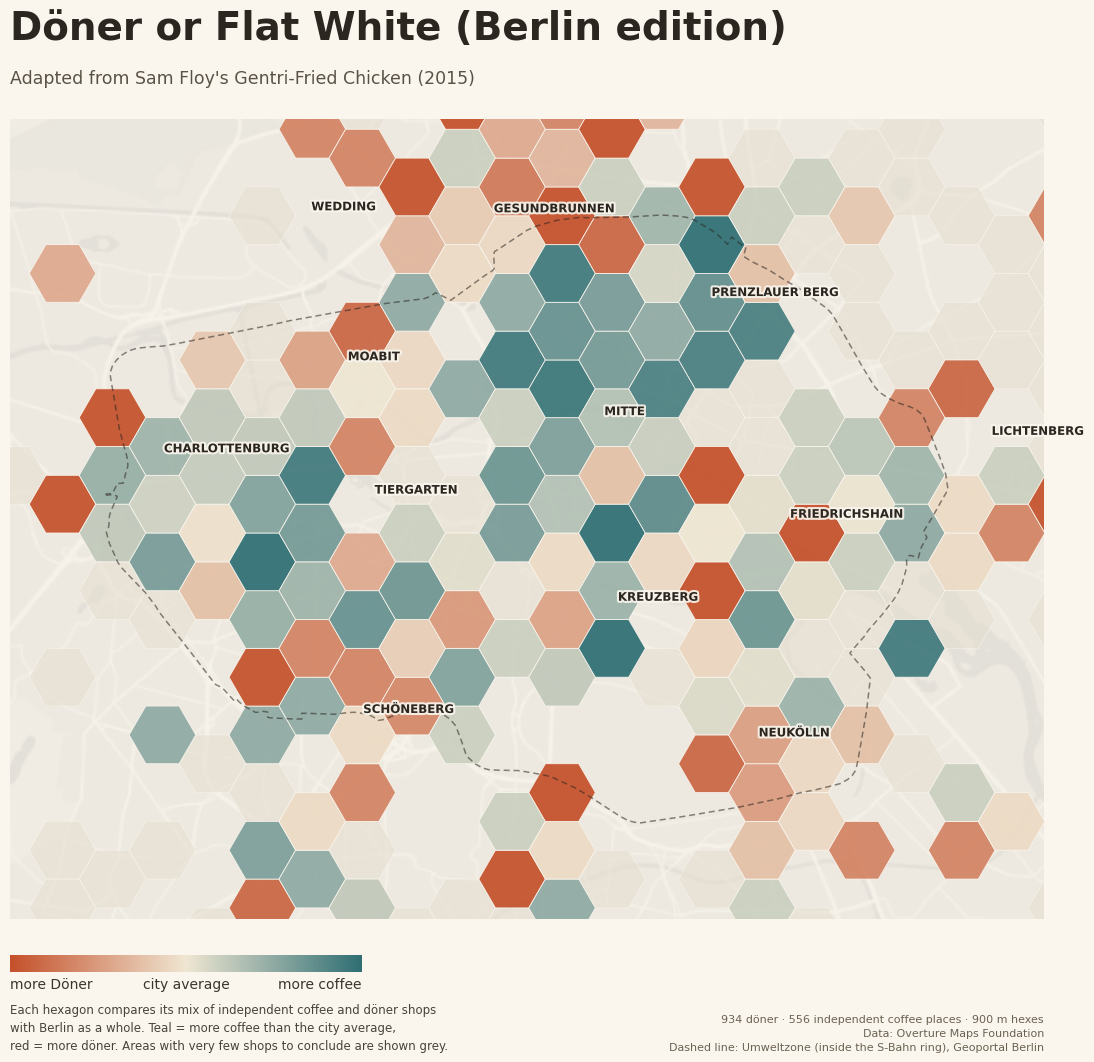

saved taste_berlin_coffee_ring_neighbourhoods.png


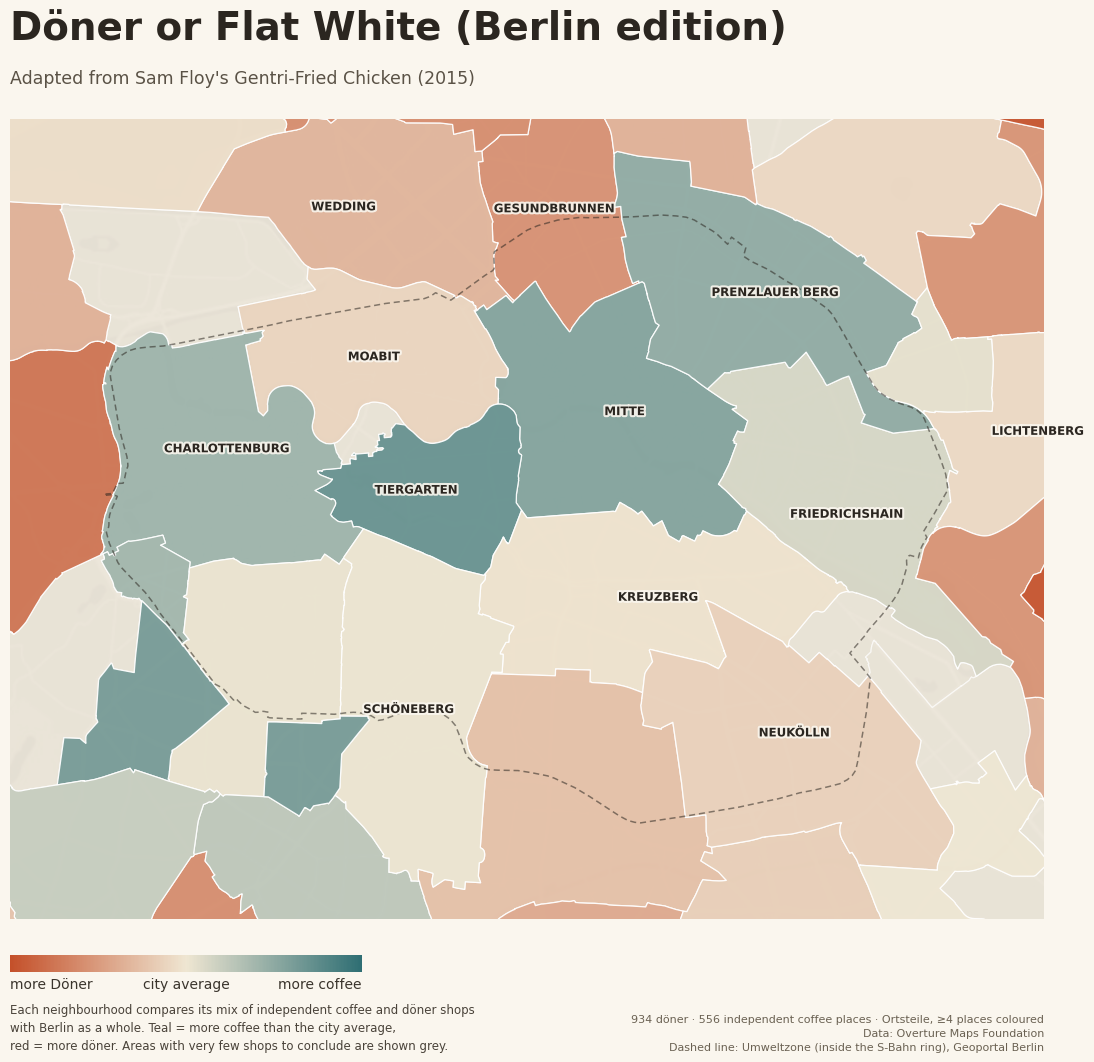

saved taste_berlin_coffee_ring_dots.png


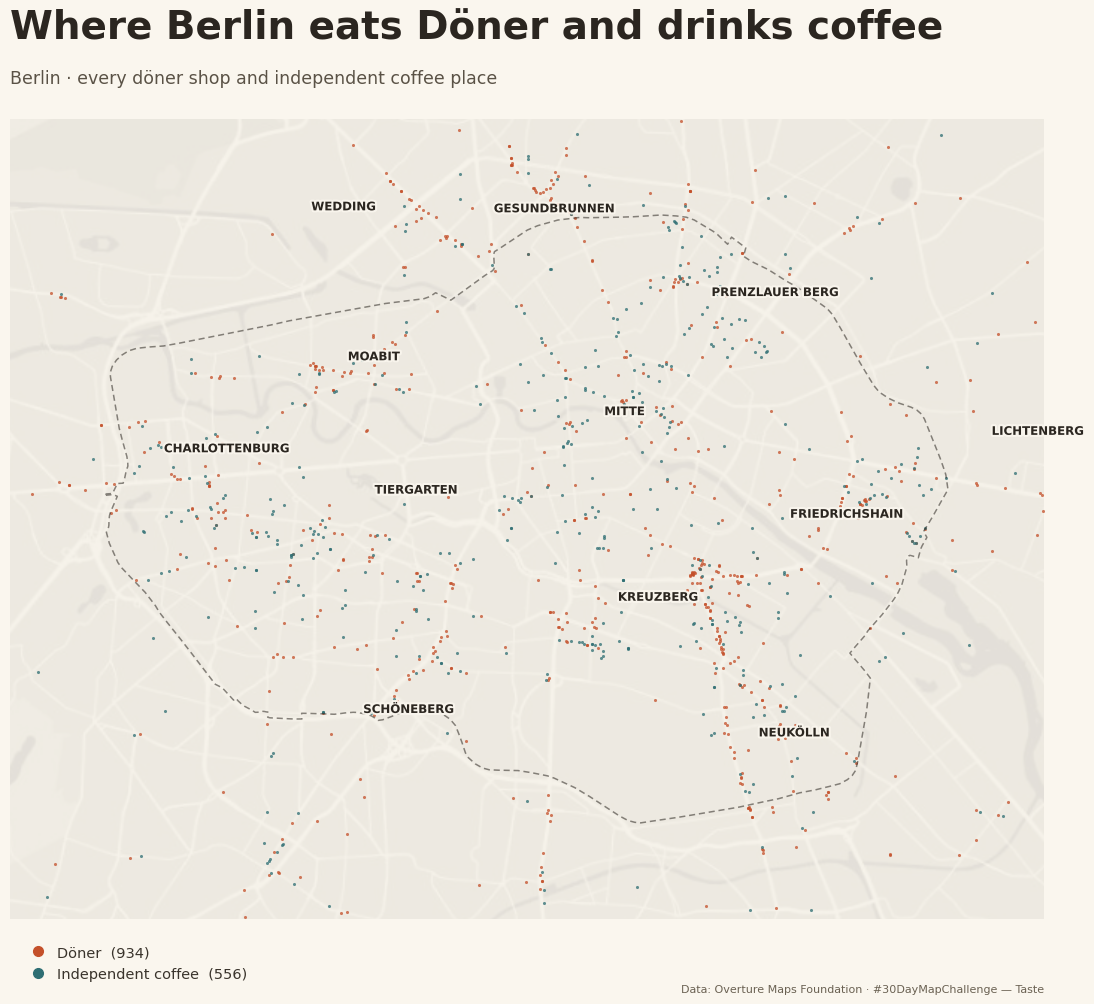


=== berlin_coffee_city ===
saved taste_berlin_coffee_city_hex.png


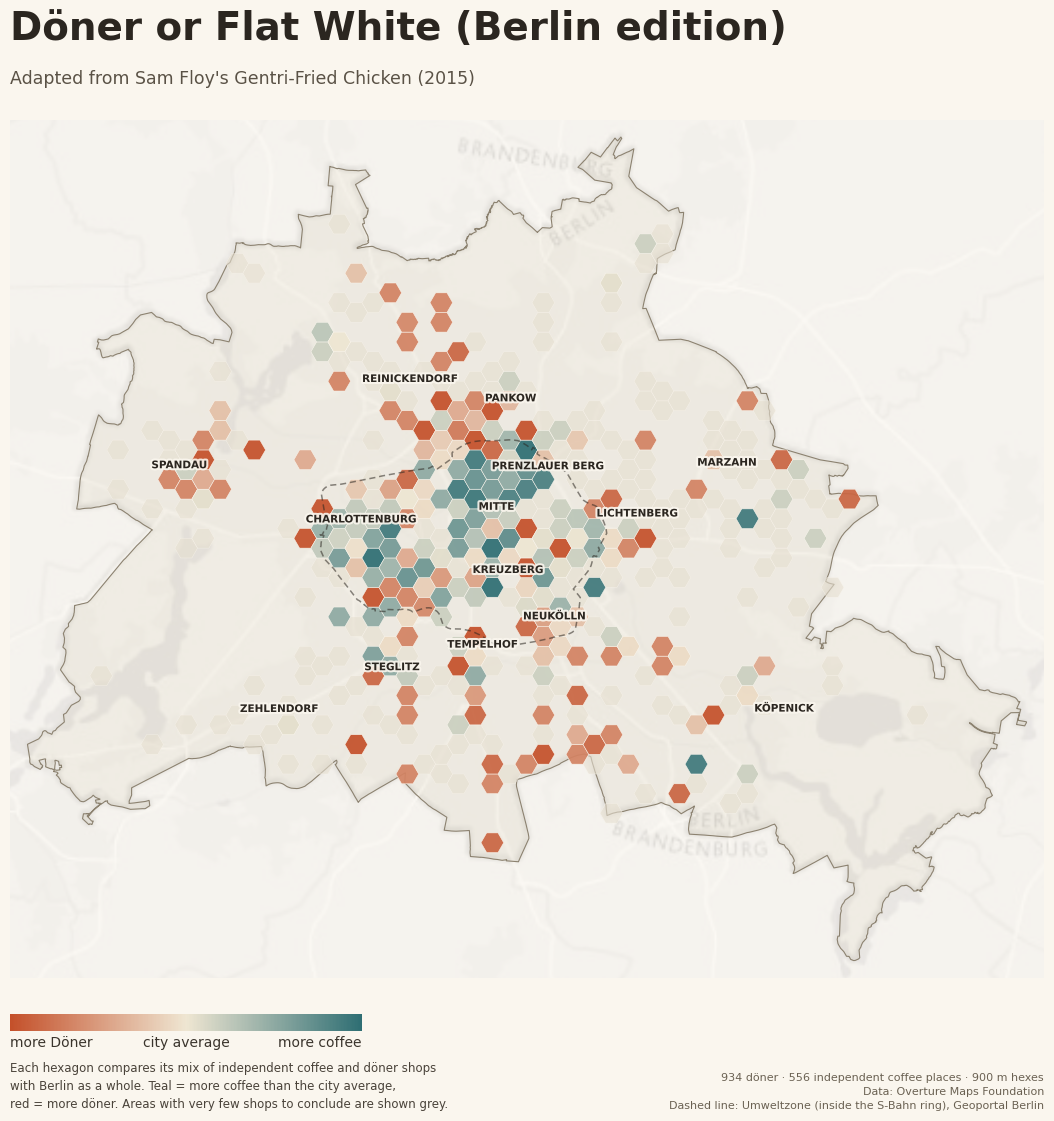

saved taste_berlin_coffee_city_neighbourhoods.png


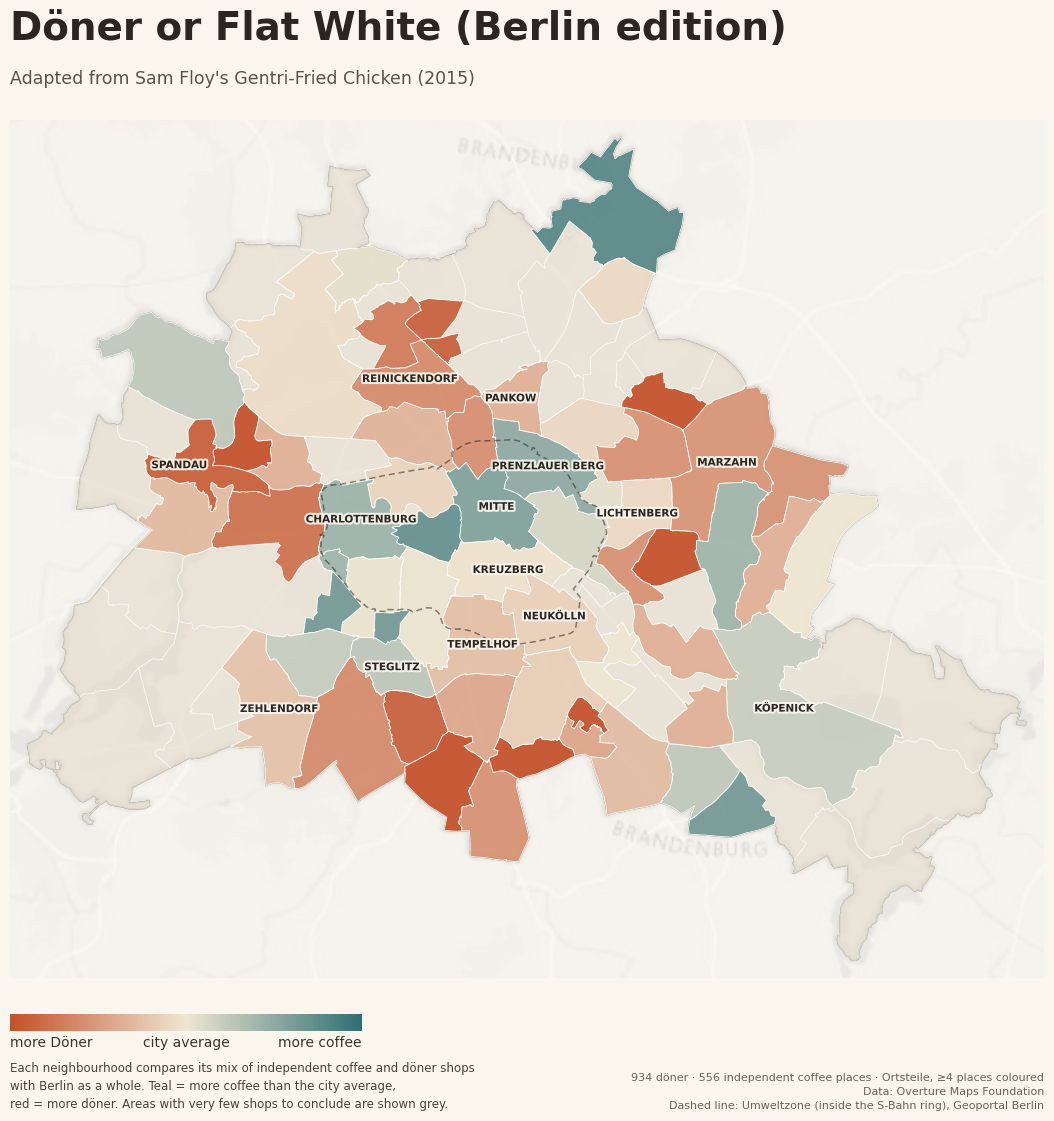

saved taste_berlin_coffee_city_dots.png


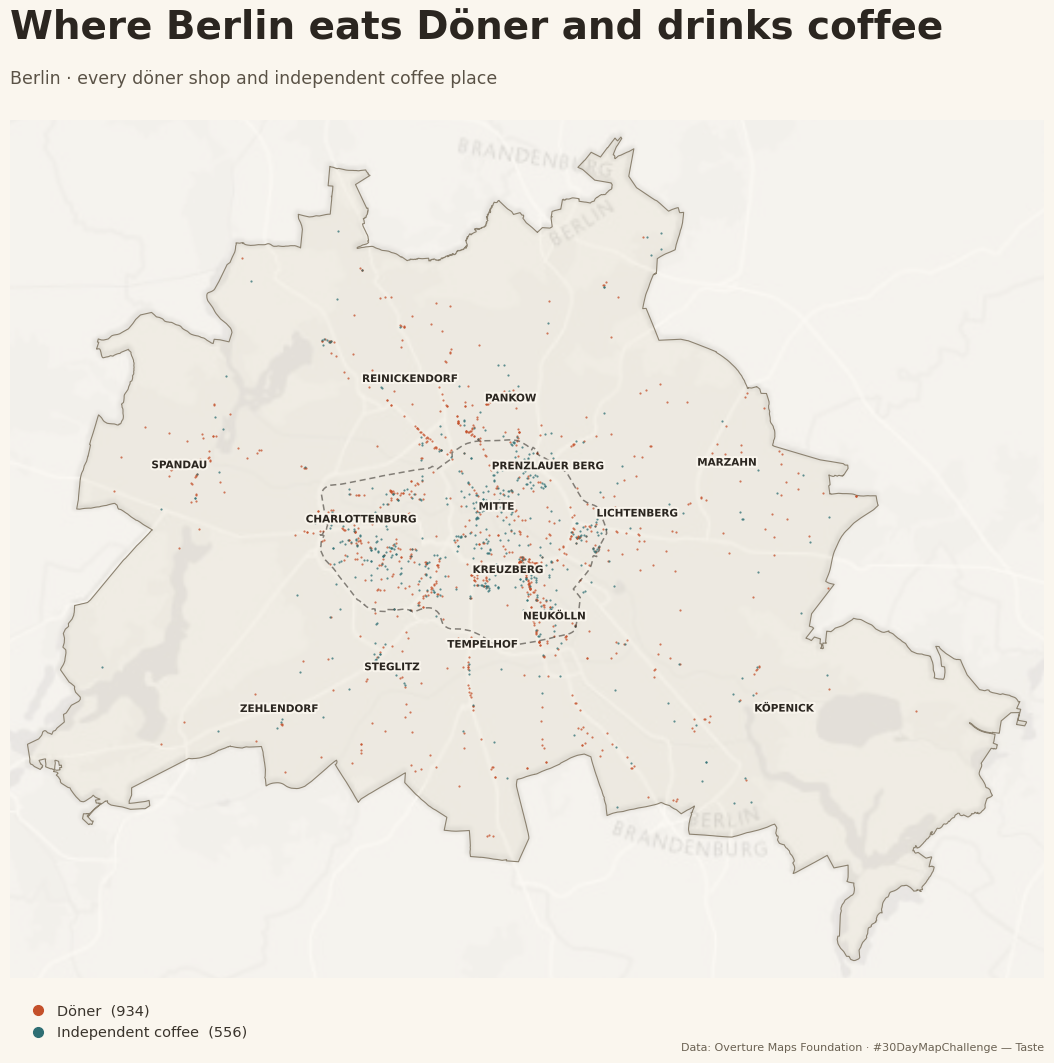

In [172]:
# One full set of maps per focus — inner city and whole city by default
for focus in FOCUSES:
    extent = get_extent(focus)
    if extent is None:
        print(f"\nSkipping '{focus}' view — no inner-city outline data")
        continue
    whole = focus == "city"
    LABELS = label_points(CFG.get("labels_city" if whole else "labels", CFG.get("labels", [])))
    LABEL_SIZE = 7.5 if whole else 8.5
    tag = f"{CITY}_{focus if isinstance(focus, str) else 'custom'}"
    print(f"\n=== {tag} ===")

    index_map(hexes, "hexagon", f"{CFG['hex_m']} m hexes",
              f"taste_{tag}_hex.png", lw=0.4 if whole else 0.6)
    if districts is not None:
        index_map(districts, "neighbourhood", f"Ortsteile, ≥{MIN_POINTS_PER_DISTRICT} places coloured",
                  f"taste_{tag}_neighbourhoods.png", edge="#FFFFFF", lw=0.6 if whole else 0.9)
    dot_map(f"taste_{tag}_dots.png", size=2.5 if whole else 5)

## 7 · Optional extras

* **Views** — `FOCUSES` controls which crops get drawn; add a `(w, s, e, n)` box for a custom zoom (e.g. just Kreuzberg–Neukölln).
* **Hex or neighbourhood?** Hexes show fine-grained hot spots; Ortsteile are easier to read and name, but big ones average out contrasts. `MIN_POINTS_PER_DISTRICT` greys out thin ones.
* **Bivariate with rents** — join `hexes` to a rent / land-value layer (Berlin: the *Bodenrichtwerte* or the *Monitoring Soziale Stadtentwicklung* status index on the Berlin Open Data portal) and recreate Floy's "high matcha + low rent = up-and-coming" layer.
* **Too sparse?** Use `B_EXTRA`, add ids to `INCLUDE_B`, bump `hex_m` to 1200–1500, or lower `OVERTURE_MIN_CONFIDENCE`.
* **Compare sources** — run once with `SOURCE="overture"` and once with `"osm"`; where they disagree is itself interesting.
* **Chains** — the coffee preset drops chains via `CHAINS` (name regex) and Overture's `brand` field. Add any local chain you spot in the sanity-check list.
* **Another city/pair** — add a preset: e.g. Seoul *chimaek vs. matcha* (note: OSM coverage in Korea is thin), London *chicken shop vs. matcha* as a 2026 update of Floy's original, or Melbourne *milk bar vs. matcha*.
* Export the layer for QGIS: `shown.to_file(f"taste_{CITY}.gpkg")`